# 04 — Clustering de Conteúdo
## Quais "tipos" de post existem no perfil da Genna?

Agrupa posts por similaridade de features usando K-Means, identifica perfis distintos e cruza com performance.

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "general_dataset.parquet")
reels = df[df["post_type"] == "REEL"].copy().reset_index(drop=True)
print(f"Reels: {len(reels)} posts")

Reels: 116 posts


In [ ]:
num_features = [
    "video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
    "image_quality_score", "curiosity_gap_level", "first_frame_scroll_stop_score",
    "creator_camera_presence_score", "educational_density",
    "controversy_level", "overall_provocation_score",
    "caption_length_chars", "hashtag_count",
]
cat_features = [
    "content_category", "narrative_structure", "emotional_arc",
    "hook_visual_technique", "visual_format_type", "voice_tone_energy",
    "opening_emotion_conveyed", "value_proposition_type",
    "target_audience_intent", "bait_and_reveal_structure",
    "caption_first_line_hook", "audio_hook_type",
]

available_cat = [f for f in cat_features if f in reels.columns and reels[f].notna().sum() > 50]
available_num = [f for f in num_features if f in reels.columns and reels[f].notna().sum() > 50]
available = available_num + available_cat

X = reels[available].copy()
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X[available_cat] = enc.fit_transform(X[available_cat].fillna("__MISSING__"))
X[available_num] = X[available_num].fillna(X[available_num].median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.values)
print(f"Features para clustering: {X_scaled.shape[1]}")

Features para clustering: 24


## 1. Encontrar número ótimo de clusters

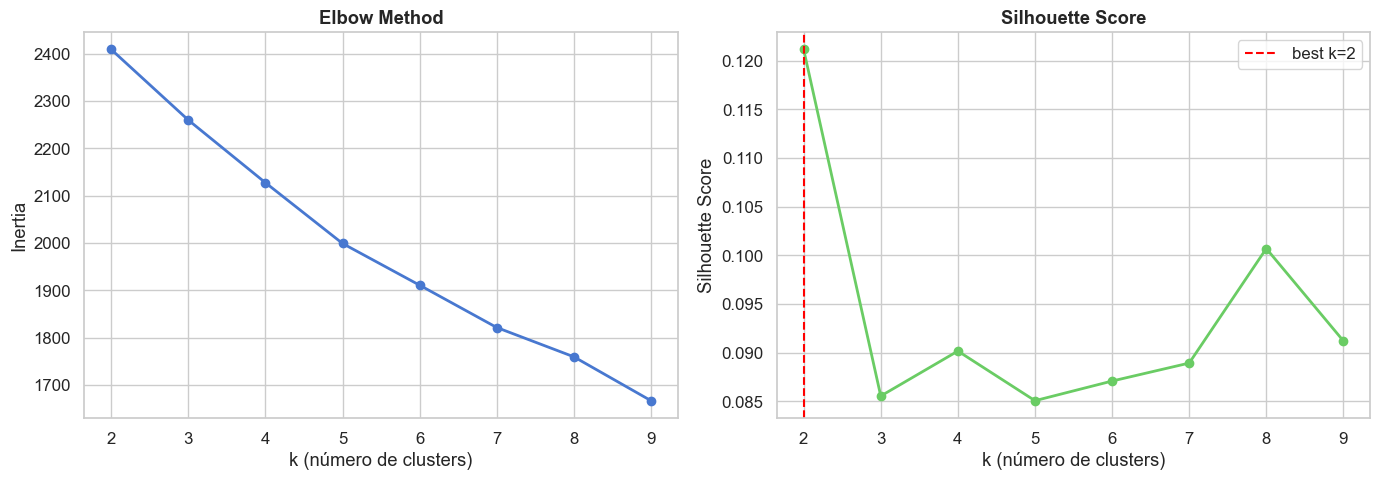

Melhor k por silhouette: 2 (score=0.121)


In [ ]:
K_range = range(2, 10)
inertias = []
silhouettes = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, "bo-", lw=2)
axes[0].set_xlabel("k (número de clusters)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method", fontweight="bold")

axes[1].plot(K_range, silhouettes, "go-", lw=2)
axes[1].set_xlabel("k (número de clusters)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score", fontweight="bold")

best_k = K_range[np.argmax(silhouettes)]
axes[1].axvline(best_k, color="red", ls="--", label=f"best k={best_k}")
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Melhor k por silhouette: {best_k} (score={max(silhouettes):.3f})")

## 2. Aplicar K-Means e visualizar com PCA

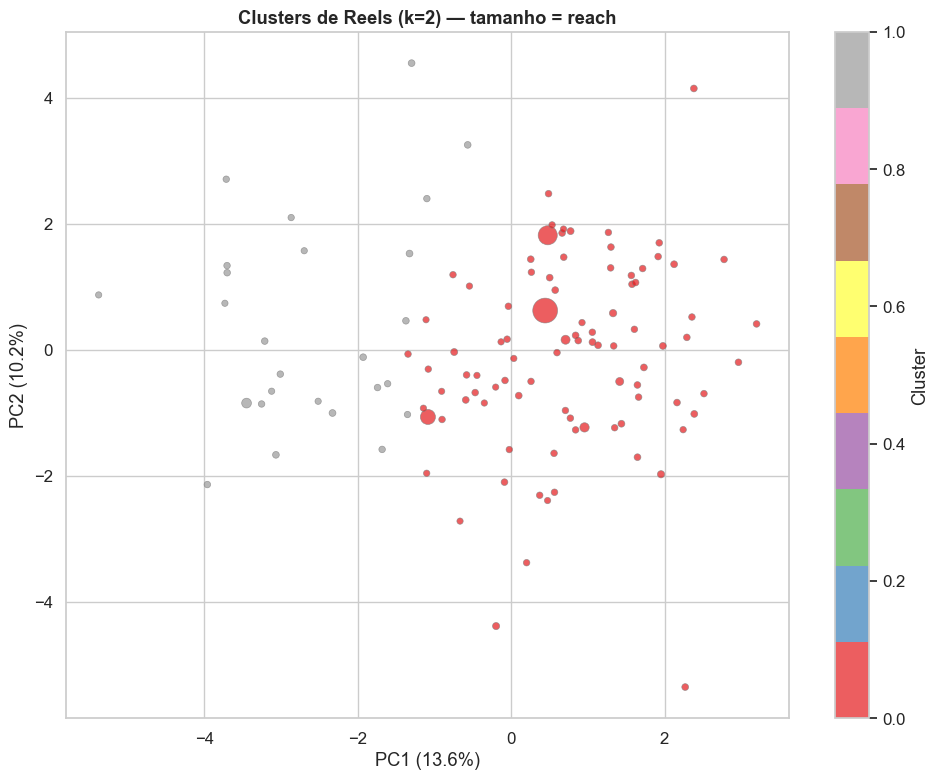

Variância explicada pelo PCA (2 componentes): 23.9%


In [ ]:
n_clusters = best_k
km = KMeans(n_clusters=n_clusters, n_init=20, random_state=42)
reels["cluster"] = km.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=reels["cluster"], cmap="Set1",
                      s=reels["reach"] / reels["reach"].max() * 300 + 20,
                      alpha=0.7, edgecolors="gray", lw=0.5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title(f"Clusters de Reels (k={n_clusters}) — tamanho = reach", fontweight="bold")
plt.colorbar(scatter, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

print(f"Variância explicada pelo PCA (2 componentes): {pca.explained_variance_ratio_.sum()*100:.1f}%")

## 3. Perfil de cada cluster

PERFORMANCE POR CLUSTER

--- Cluster 0 (90 Reels) ---
                      reach: mediana=     2,496  média=     7,863
                      views: mediana=     3,225  média=    10,064
                      likes: mediana=       146  média=       740
                     shares: mediana=        48  média=       234
                      saved: mediana=        19  média=        56
         avg_watch_time_sec: mediana=        25  média=        26

--- Cluster 1 (26 Reels) ---
                      reach: mediana=     1,690  média=     2,534
                      views: mediana=     2,014  média=     3,030
                      likes: mediana=        55  média=       167
                     shares: mediana=         6  média=        33
                      saved: mediana=         7  média=        17
         avg_watch_time_sec: mediana=        19  média=        19


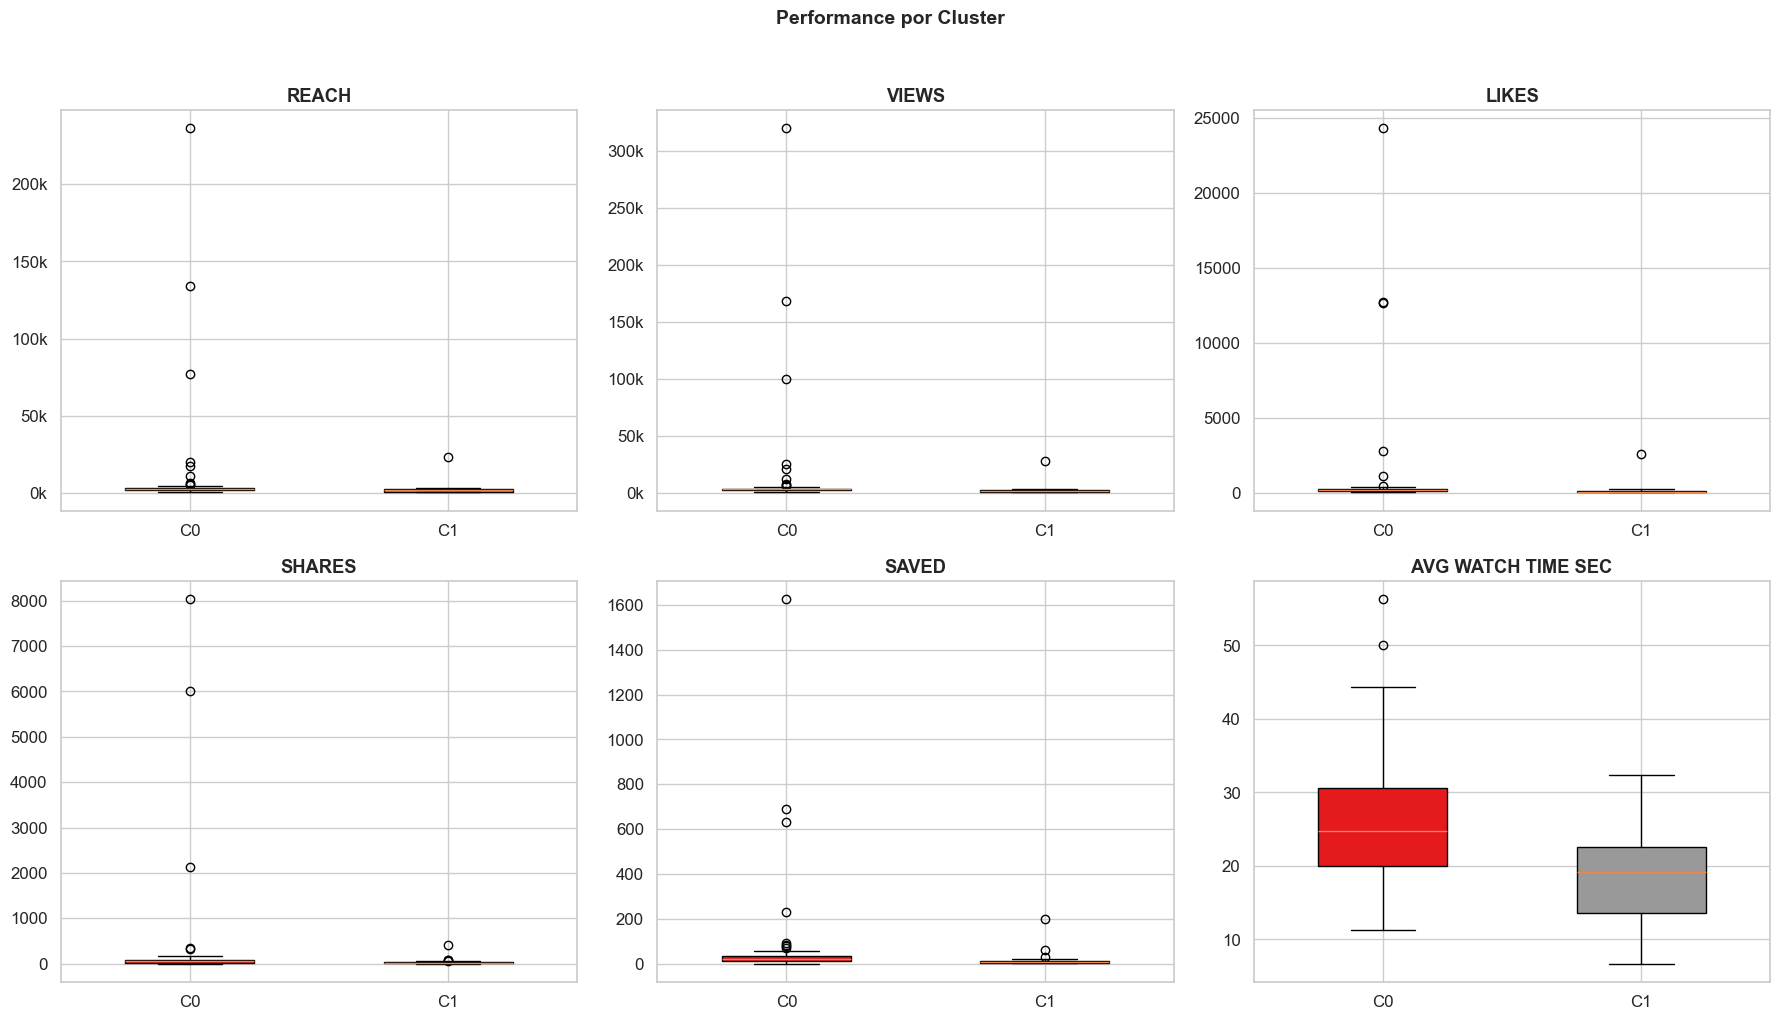

In [ ]:
perf_metrics = ["reach", "views", "likes", "shares", "saved", "avg_watch_time_sec"]

print("=" * 70)
print("PERFORMANCE POR CLUSTER")
print("=" * 70)
for c in sorted(reels["cluster"].unique()):
    subset = reels[reels["cluster"] == c]
    print(f"\n--- Cluster {c} ({len(subset)} Reels) ---")
    for m in perf_metrics:
        vals = subset[m].dropna()
        if len(vals) > 0:
            print(f"  {m:>25s}: mediana={vals.median():>10,.0f}  média={vals.mean():>10,.0f}")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, metric in zip(axes.flat, perf_metrics):
    data_per_cluster = [reels[reels["cluster"] == c][metric].dropna() for c in sorted(reels["cluster"].unique())]
    bp = ax.boxplot(data_per_cluster, labels=[f"C{c}" for c in sorted(reels["cluster"].unique())],
                     patch_artist=True, widths=0.5)
    colors = plt.cm.Set1(np.linspace(0, 1, n_clusters))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
    ax.set_title(metric.replace("_", " ").upper(), fontweight="bold")
    if metric in ["reach", "views"]:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

fig.suptitle("Performance por Cluster", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. Características dominantes de cada cluster

In [ ]:
profile_cats = ["content_category", "narrative_structure", "emotional_arc",
                "hook_visual_technique", "voice_tone_energy", "value_proposition_type"]

print("=" * 70)
print("PERFIL CATEGÓRICO POR CLUSTER")
print("=" * 70)
for c in sorted(reels["cluster"].unique()):
    subset = reels[reels["cluster"] == c]
    print(f"\n--- Cluster {c} ({len(subset)} Reels, reach mediano={subset['reach'].median():,.0f}) ---")
    for feat in profile_cats:
        mode = subset[feat].dropna().mode()
        if len(mode) > 0:
            pct = (subset[feat] == mode.iloc[0]).sum() / len(subset) * 100
            print(f"  {feat:>30s}: {mode.iloc[0]:>30s} ({pct:.0f}%)")

profile_nums = ["video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
                "curiosity_gap_level", "educational_density", "caption_length_chars"]

print(f"\n{'='*70}")
print("PERFIL NUMÉRICO POR CLUSTER (medianas)")
print("=" * 70)
print(f"{'Feature':>30s}", end="")
for c in sorted(reels["cluster"].unique()):
    print(f"  {'C'+str(c):>10s}", end="")
print()
print("-" * (30 + 12 * n_clusters))

for feat in profile_nums:
    print(f"{feat:>30s}", end="")
    for c in sorted(reels["cluster"].unique()):
        val = reels[reels["cluster"] == c][feat].dropna().median()
        print(f"  {val:>10.1f}", end="")
    print()

PERFIL CATEGÓRICO POR CLUSTER

--- Cluster 0 (90 Reels, reach mediano=2,496) ---
                content_category:         motivation_inspiration (61%)
             narrative_structure:                      story_arc (58%)
                   emotional_arc:                 positive_build (91%)
           hook_visual_technique:                      text_hook (93%)
               voice_tone_energy:        confident_authoritative (79%)
          value_proposition_type:                learn_something (57%)

--- Cluster 1 (26 Reels, reach mediano=1,690) ---
                content_category:               opinion_hot_take (46%)
             narrative_structure:               problem_solution (69%)
                   emotional_arc:                flat_consistent (65%)
           hook_visual_technique:                      text_hook (92%)
               voice_tone_energy:        confident_authoritative (96%)
          value_proposition_type:                learn_something (92%)

PERFIL NUMÉRICO

## 5. Radar Chart: Perfil Numérico por Cluster (normalizado)

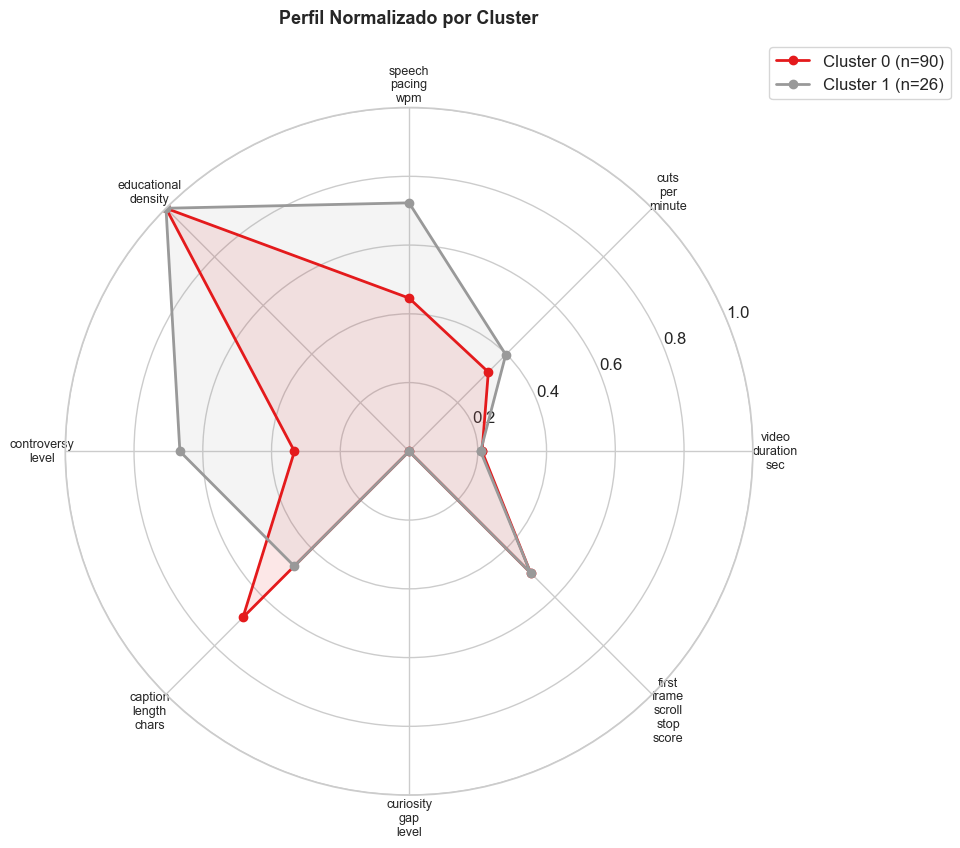

In [ ]:
radar_feats = ["video_duration_sec", "cuts_per_minute", "speech_pacing_wpm",
               "educational_density", "controversy_level", "caption_length_chars",
               "curiosity_gap_level", "first_frame_scroll_stop_score"]

cluster_medians = reels.groupby("cluster")[radar_feats].median()
global_min = reels[radar_feats].min()
global_max = reels[radar_feats].max()
normalized = (cluster_medians - global_min) / (global_max - global_min + 1e-9)

labels = [f.replace("_", "\n") for f in radar_feats]
n_feats = len(radar_feats)
angles = np.linspace(0, 2 * np.pi, n_feats, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colors_radar = plt.cm.Set1(np.linspace(0, 1, n_clusters))

for c in sorted(reels["cluster"].unique()):
    values = normalized.loc[c].tolist()
    values += values[:1]
    ax.plot(angles, values, "o-", lw=2, color=colors_radar[c], label=f"Cluster {c} (n={len(reels[reels['cluster']==c])})")
    ax.fill(angles, values, alpha=0.1, color=colors_radar[c])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 1)
ax.set_title("Perfil Normalizado por Cluster", fontweight="bold", fontsize=13, pad=30)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

## 6. Timeline: Clusters ao longo do tempo

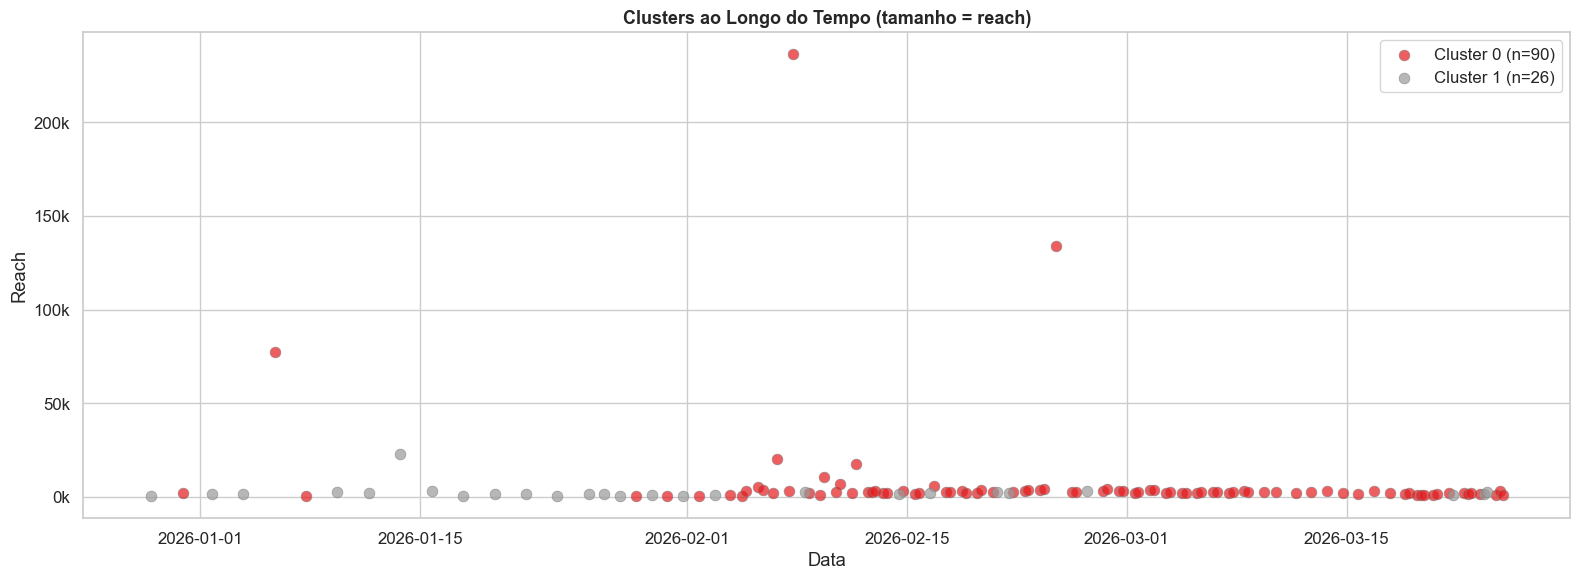

Distribuição temporal dos clusters:
cluster   0   1
month          
2025-12   1   1
2026-01   4  15
2026-02  45   7
2026-03  40   3


In [ ]:
fig, ax = plt.subplots(figsize=(16, 6))

colors_timeline = plt.cm.Set1(np.linspace(0, 1, n_clusters))
for c in sorted(reels["cluster"].unique()):
    subset = reels[reels["cluster"] == c]
    ax.scatter(subset["date_br"], subset["reach"], c=[colors_timeline[c]], s=60,
               alpha=0.7, label=f"Cluster {c} (n={len(subset)})", edgecolors="gray", lw=0.5)

ax.set_xlabel("Data")
ax.set_ylabel("Reach")
ax.set_title("Clusters ao Longo do Tempo (tamanho = reach)", fontweight="bold", fontsize=13)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.legend()
plt.tight_layout()
plt.show()

print("Distribuição temporal dos clusters:")
reels["month"] = reels["date_br"].dt.to_period("M").astype(str)
ct = pd.crosstab(reels["month"], reels["cluster"])
print(ct.to_string())

## 7. Resumo e Nomeação dos Clusters

In [ ]:
print("=" * 60)
print("RESUMO DOS CLUSTERS")
print("=" * 60)
print(f"\nk = {n_clusters} clusters identificados via K-Means")
print(f"Silhouette Score: {silhouette_score(X_scaled, reels['cluster']):.3f}\n")

for c in sorted(reels["cluster"].unique()):
    subset = reels[reels["cluster"] == c]
    print(f"--- Cluster {c} ---")
    print(f"  Tamanho: {len(subset)} Reels ({len(subset)/len(reels)*100:.0f}%)")
    print(f"  Reach mediano: {subset['reach'].median():,.0f}")
    print(f"  Shares mediano: {subset['shares'].median():,.0f}")
    
    top_cat = subset["content_category"].dropna().mode()
    top_narr = subset["narrative_structure"].dropna().mode()
    top_tone = subset["voice_tone_energy"].dropna().mode()
    top_hook = subset["hook_visual_technique"].dropna().mode()
    
    if len(top_cat) > 0:
        print(f"  Content category: {top_cat.iloc[0]}")
    if len(top_narr) > 0:
        print(f"  Narrative: {top_narr.iloc[0]}")
    if len(top_tone) > 0:
        print(f"  Voice tone: {top_tone.iloc[0]}")
    if len(top_hook) > 0:
        print(f"  Hook visual: {top_hook.iloc[0]}")
    print(f"  Duration: {subset['video_duration_sec'].median():.0f}s")
    print(f"  Cuts/min: {subset['cuts_per_minute'].median():.1f}")
    print()

RESUMO DOS CLUSTERS

k = 2 clusters identificados via K-Means
Silhouette Score: 0.121

--- Cluster 0 ---
  Tamanho: 90 Reels (78%)
  Reach mediano: 2,496
  Shares mediano: 48
  Content category: motivation_inspiration
  Narrative: story_arc
  Voice tone: confident_authoritative
  Hook visual: text_hook
  Duration: 85s
  Cuts/min: 9.9

--- Cluster 1 ---
  Tamanho: 26 Reels (22%)
  Reach mediano: 1,690
  Shares mediano: 6
  Content category: opinion_hot_take
  Narrative: problem_solution
  Voice tone: confident_authoritative
  Hook visual: text_hook
  Duration: 84s
  Cuts/min: 11.9

